<center><h1>Hong_Brandon_HW6</h1></center>

Name: Brandon Hong
<br>
Github Username: bwhong
<br>
USC ID: 3091232124

## 1. Tree-Based Methods

Import packages

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score, f1_score
from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [53]:
train_data = pd.read_csv('../data/aps_failure_training_set.csv', skiprows = 20, na_values = 'na')
train_data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [54]:
test_data = pd.read_csv('../data/aps_failure_test_set.csv', skiprows = 20, na_values = 'na')
test_data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0


### (b) Data Preparation

In [55]:
train_data.describe()

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
count,6.000000e+04,13671.000000,5.666500e+04,4.513900e+04,57500.000000,57500.000000,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,...,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,5.932900e+04,57276.000000,57277.000000
mean,5.933650e+04,0.713189,3.560143e+08,1.906206e+05,6.819130,11.006817,2.216364e+02,9.757223e+02,8.606015e+03,8.859128e+04,...,4.454897e+05,2.111264e+05,4.457343e+05,3.939462e+05,3.330582e+05,3.462714e+05,1.387300e+05,8.388915e+03,0.090579,0.212756
std,1.454301e+05,3.478962,7.948749e+08,4.040441e+07,161.543373,209.792592,2.047846e+04,3.420053e+04,1.503220e+05,7.617312e+05,...,1.155540e+06,5.433188e+05,1.168314e+06,1.121044e+06,1.069160e+06,1.728056e+06,4.495100e+05,4.747043e+04,4.368855,8.830641
min,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,8.340000e+02,0.000000,1.600000e+01,2.400000e+01,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,2.936000e+03,1.166000e+03,2.700000e+03,3.584000e+03,5.120000e+02,1.100000e+02,0.000000e+00,0.000000e+00,0.000000,0.000000
50%,3.077600e+04,0.000000,1.520000e+02,1.260000e+02,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,2.337960e+05,1.120860e+05,2.215180e+05,1.899880e+05,9.243200e+04,4.109800e+04,3.812000e+03,0.000000e+00,0.000000,0.000000
75%,4.866800e+04,0.000000,9.640000e+02,4.300000e+02,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,4.383960e+05,2.182320e+05,4.666140e+05,4.032220e+05,2.750940e+05,1.678140e+05,1.397240e+05,2.028000e+03,0.000000,0.000000
max,2.746564e+06,204.000000,2.130707e+09,8.584298e+09,21050.000000,20070.000000,3.376892e+06,4.109372e+06,1.055286e+07,6.340207e+07,...,7.793393e+07,3.775839e+07,9.715238e+07,5.743524e+07,3.160781e+07,1.195801e+08,1.926740e+07,3.810078e+06,482.000000,1146.000000


In [56]:
train_data.isna().sum()[train_data.isna().sum() > 0].sort_values(ascending = False)

br_000    49264
bq_000    48722
bp_000    47740
bo_000    46333
ab_000    46329
          ...  
by_000      473
ci_000      338
cj_000      338
ck_000      338
bt_000      167
Length: 169, dtype: int64

(array([2.084e+03, 2.850e+03, 1.663e+03, 5.920e+02, 2.020e+02, 5.600e+01,
        6.000e+00, 1.000e+00, 0.000e+00, 3.824e+03]),
 array([      0.,  131070.,  262140.,  393210.,  524280.,  655350.,
         786420.,  917490., 1048560., 1179630., 1310700.]),
 <BarContainer object of 10 artists>)

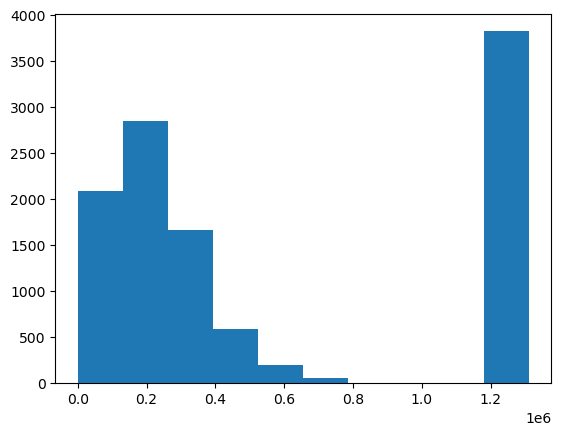

In [57]:
plt.hist(train_data['bq_000'])

(array([2.090e+03, 2.431e+03, 1.517e+03, 5.640e+02, 1.820e+02, 5.400e+01,
        1.100e+01, 1.000e+00, 0.000e+00, 3.886e+03]),
 array([      0.,  131070.,  262140.,  393210.,  524280.,  655350.,
         786420.,  917490., 1048560., 1179630., 1310700.]),
 <BarContainer object of 10 artists>)

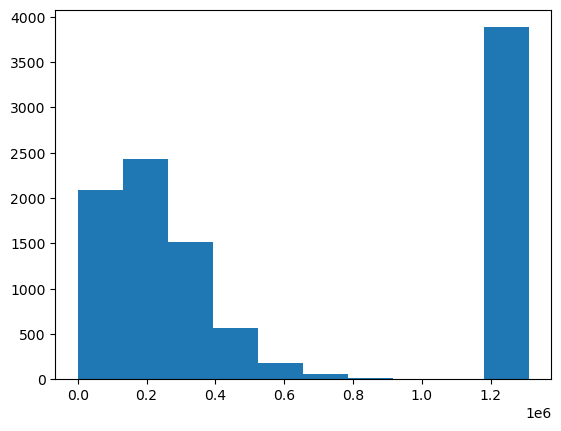

In [58]:
plt.hist(train_data['br_000'])

#### (i) Research what types of techniques are usually used

There are a couple techniques we use for data imputation. The first one would be to use a statistic such as mean, median, or mode to replace missing values. Another method would be to using a model to replace missing values. There is also the method of deleting rows with null values or columns with null values. However, this is only preferred when there is a mass amount of data. In this case, I will use median imputation.

In [59]:
train_data['class'] = train_data['class'].map({'neg': 0, 'pos': 1})
train_data.fillna(train_data.median(), inplace = True)
train_data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,0,76698,0.0,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,0,33058,0.0,0.000000e+00,126.0,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,0,41040,0.0,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,0,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,0,60874,0.0,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


#### (ii) Calculate the coefficient of variation

In [60]:
X_train = train_data.drop(columns = {'class'})
y_train = train_data['class']

In [61]:
cv_list = []
for i in X_train:
    std = X_train[i].std()
    mean = X_train[i].mean()
    cv = std / mean
    cv_list.append(cv)
cv_list[:5]

[np.float64(2.450937577943999),
 np.float64(10.383493866617679),
 np.float64(2.310240655003492),
 np.float64(244.32281575936082),
 np.float64(24.200136597481663)]

In [62]:
data = {'Feature Names': X_train.columns, 'Coefficient of Variation': cv_list}
cv_df = pd.DataFrame(data)
cv_df

,Feature Names,Coefficient of Variation
0,aa_000,2.450938
1,ab_000,10.383494
2,ac_000,2.310241
3,ad_000,244.322816
4,ae_000,24.200137
...,...,...
165,ee_007,5.012754
166,ee_008,3.259079
167,ee_009,5.691612
168,ef_000,49.366659


#### (iii) Plot a correlation matrix

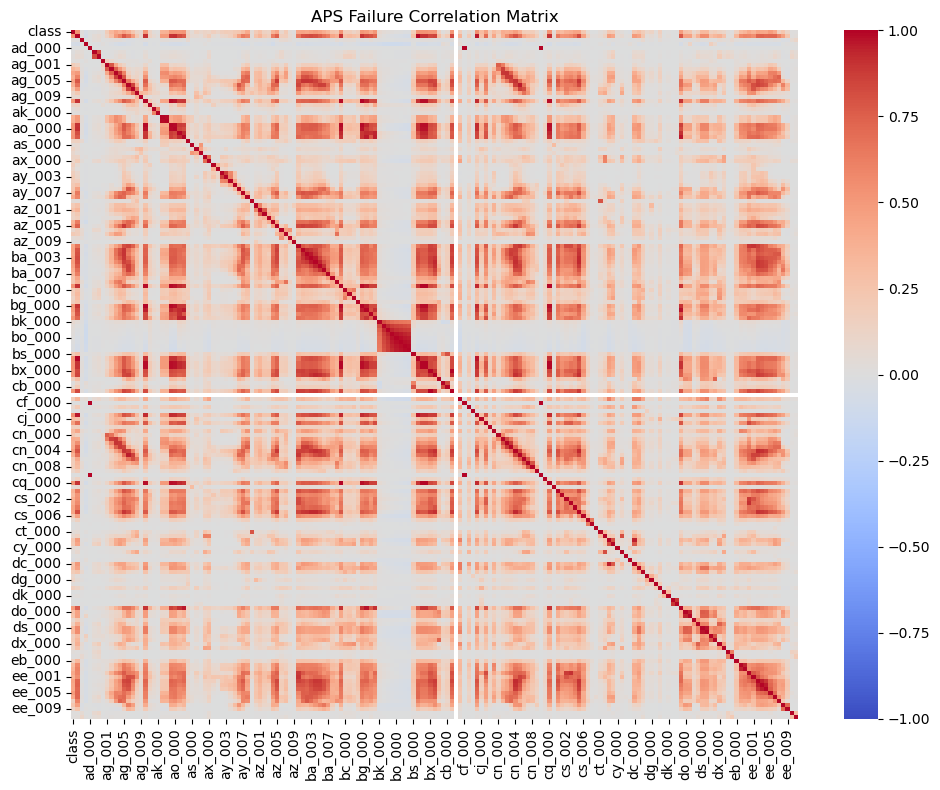

In [ ]:
corr_matrix = train_data.corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",  
    fmt=".2f", 
    vmin=-1,
    vmax=1
)

plt.title("APS Failure Correlation Matrix")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

In [64]:
170 ** (1/2)

13.038404810405298

In [65]:
cv_df_top_features = cv_df.sort_values('Coefficient of Variation', ascending=False).head(13)
cv_df_top_features

,Feature Names,Coefficient of Variation
91,cf_000,244.887517
109,co_000,244.507385
3,ad_000,244.322816
122,cs_009,237.930554
136,dh_000,123.216097
138,dj_000,117.494225
6,ag_000,92.917755
27,as_000,87.332500
41,ay_009,84.733735
19,ak_000,80.424975


Text(0.5, 0.98, 'Pairplot of Top Features vs Class')

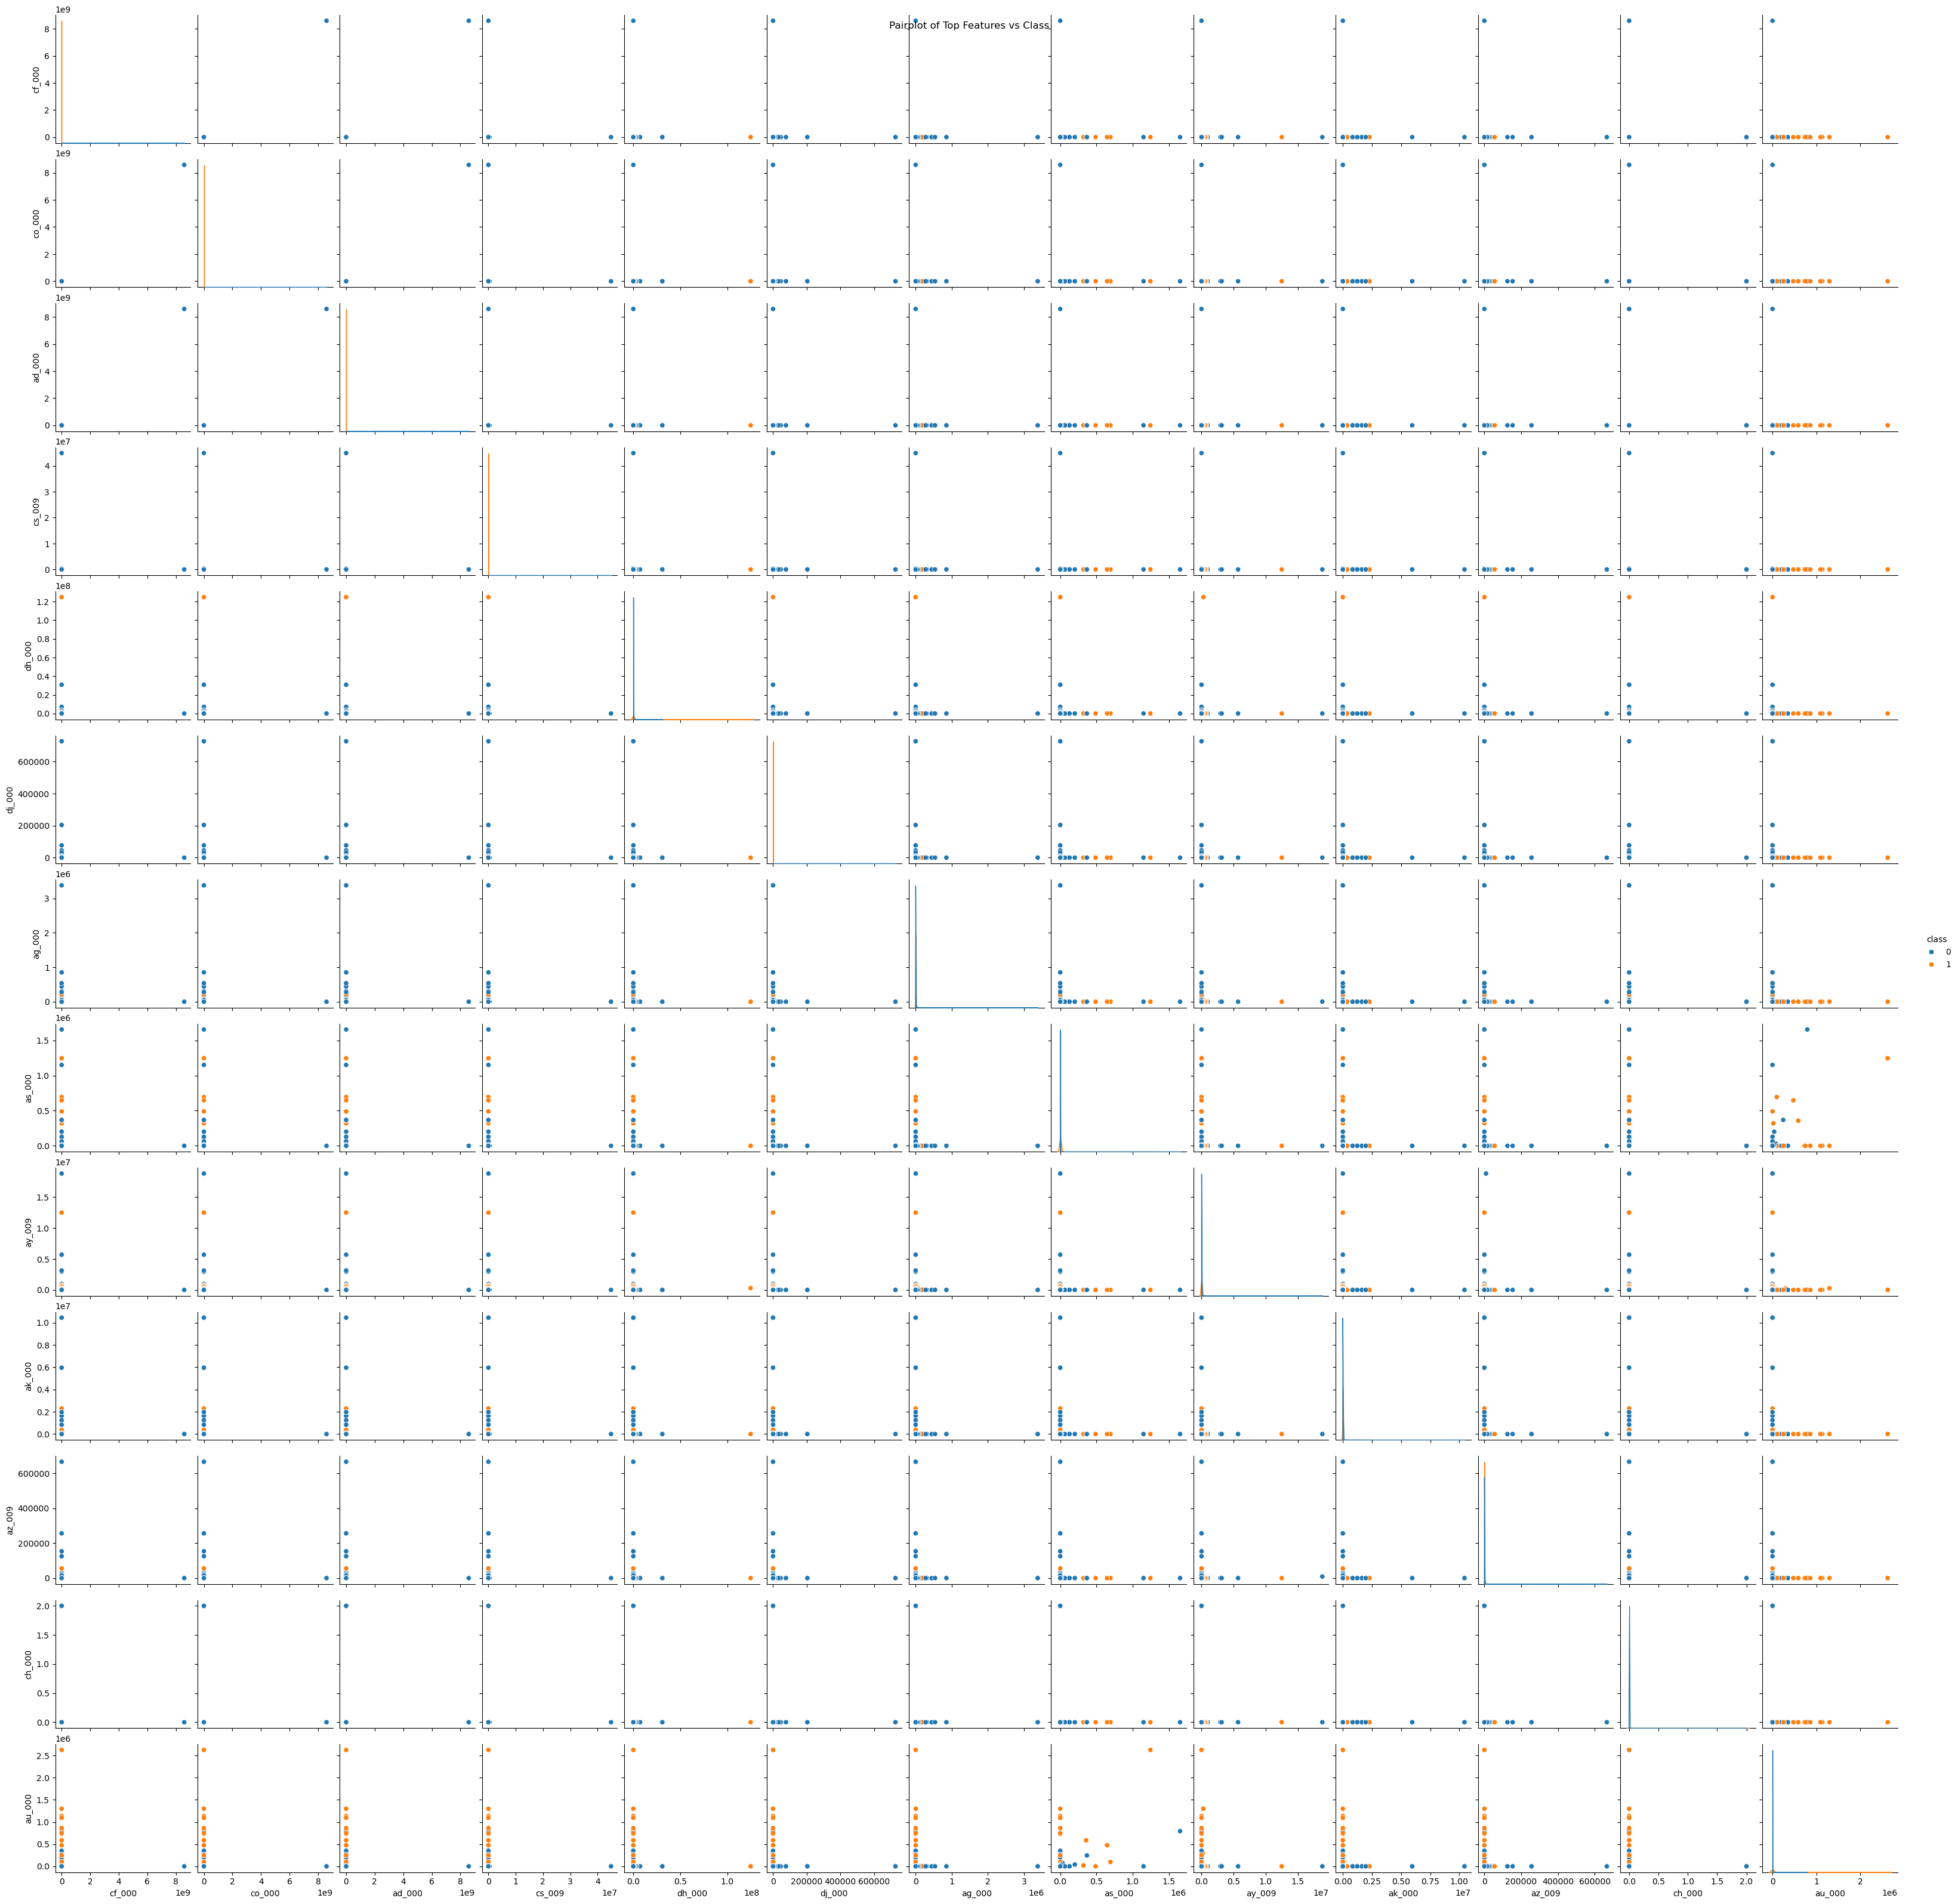

In [66]:
sns.pairplot(train_data, vars=cv_df_top_features['Feature Names'].to_list(), hue='class')
plt.suptitle("Pairplot of Top Features vs Class")

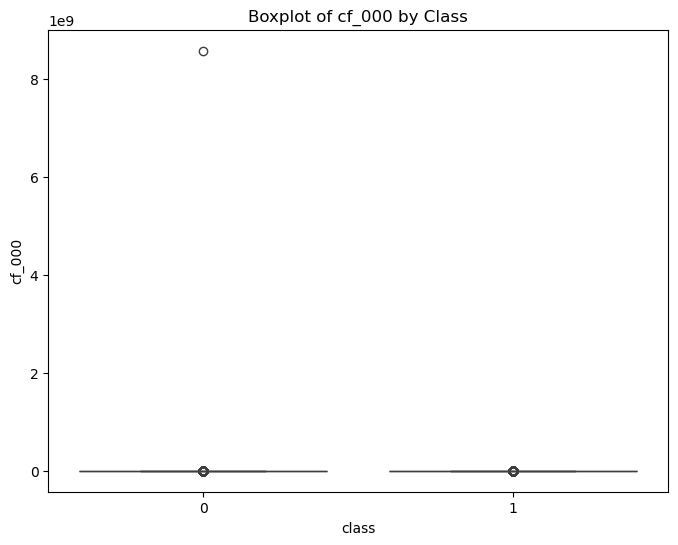

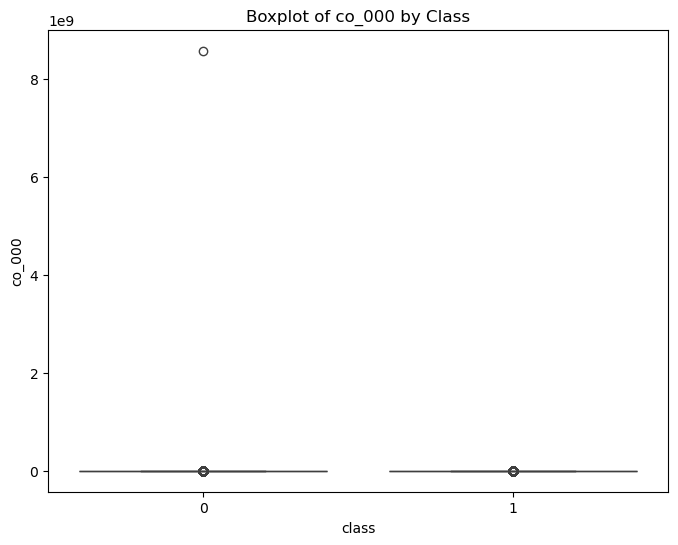

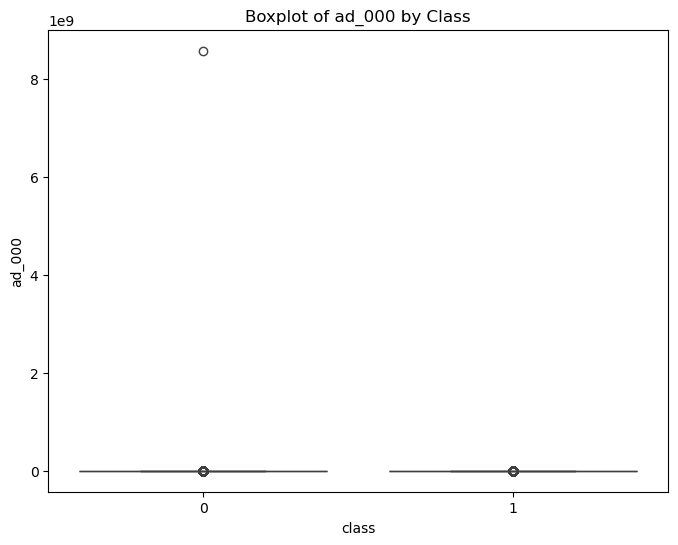

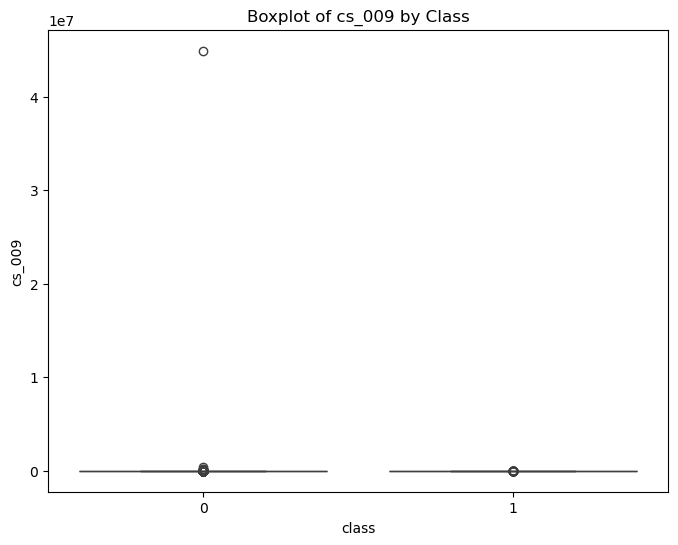

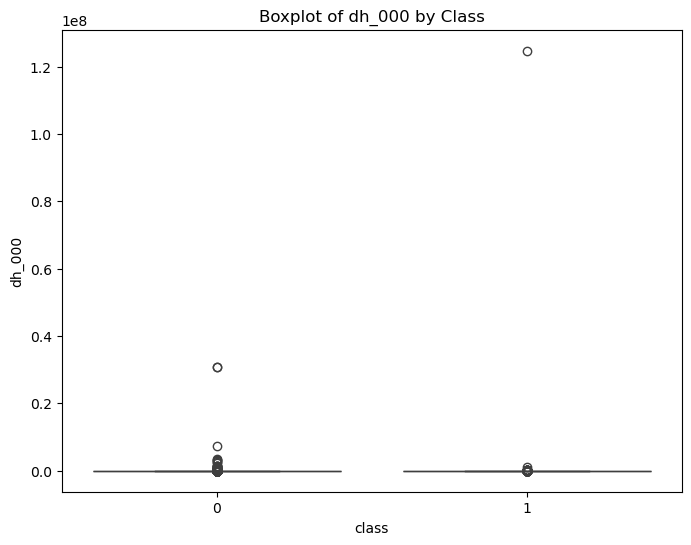

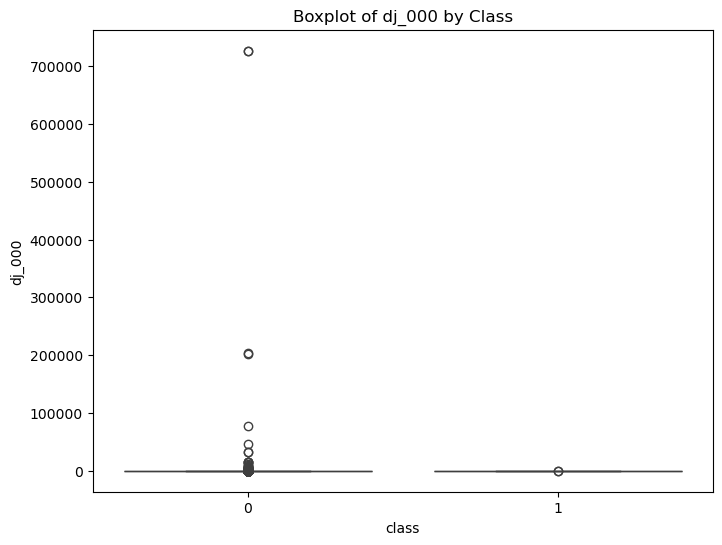

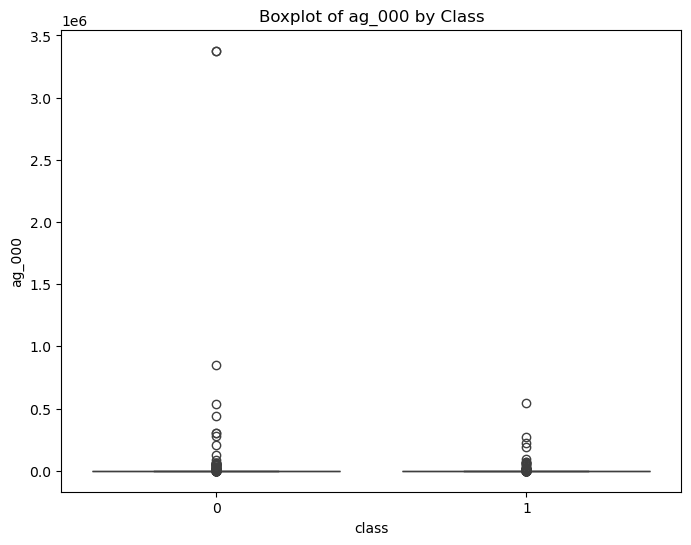

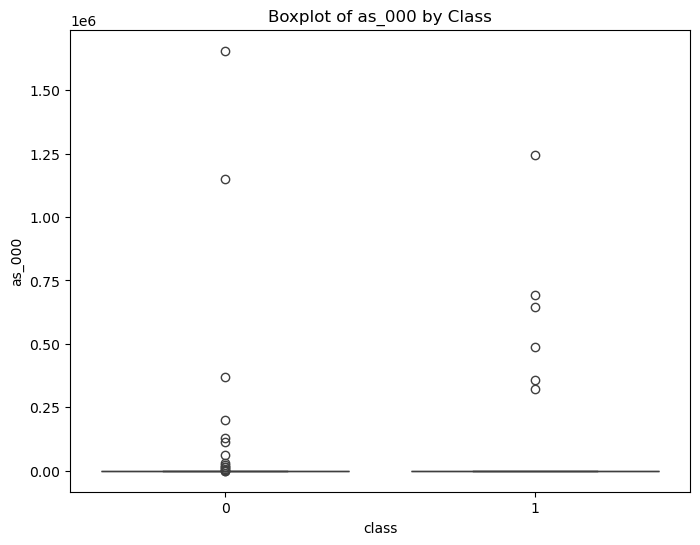

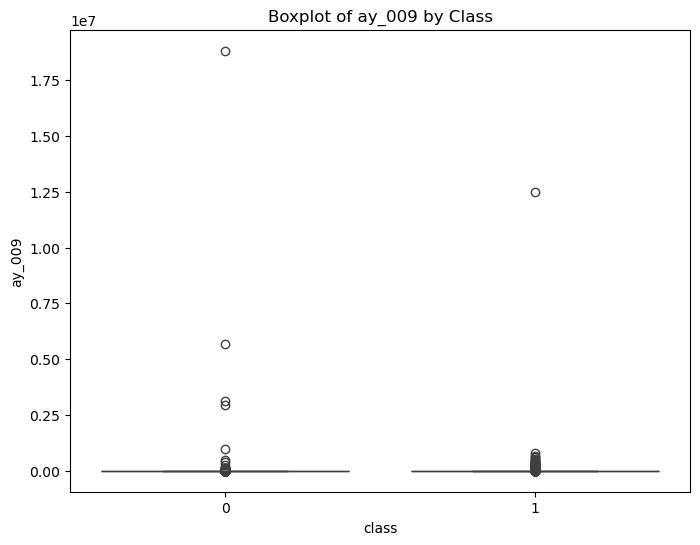

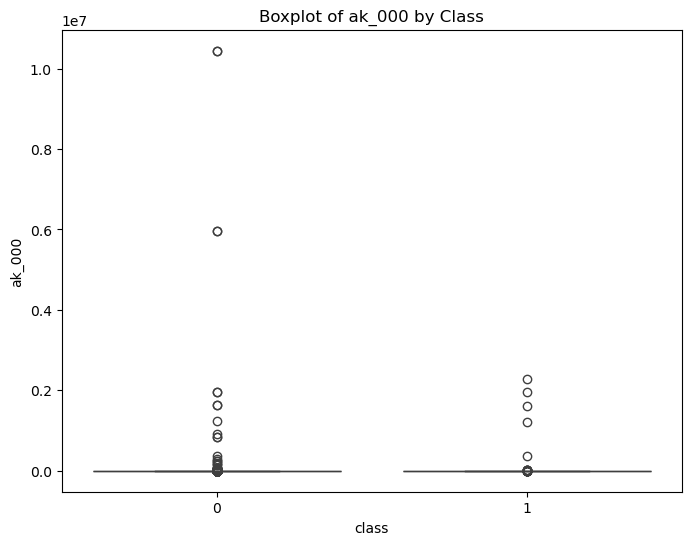

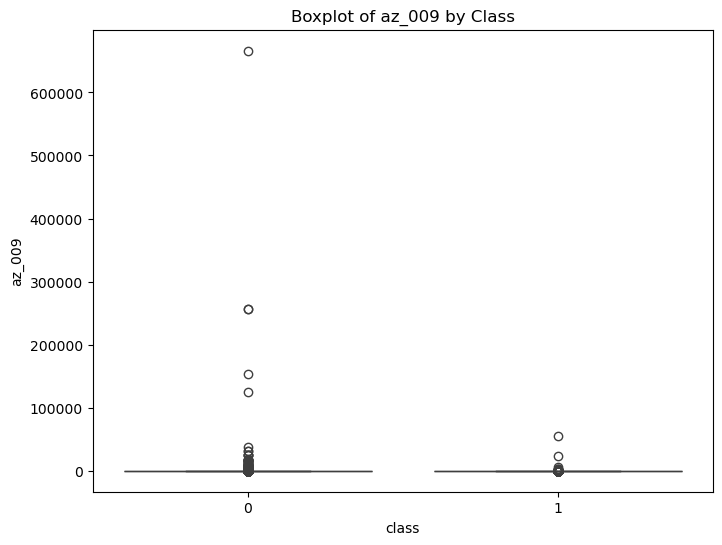

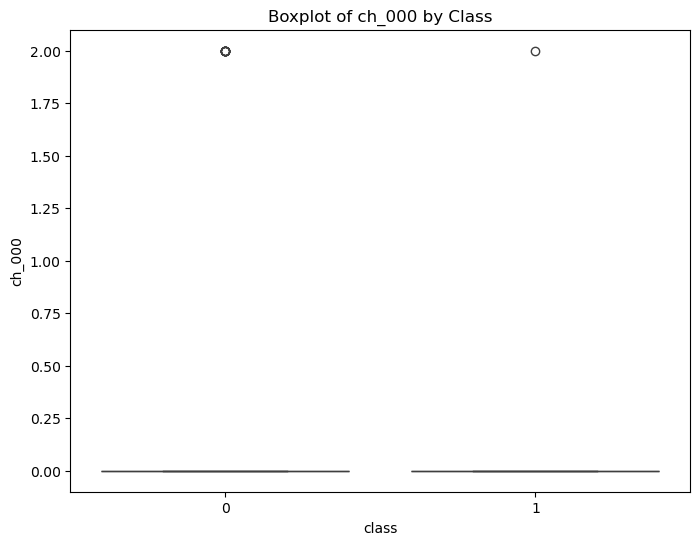

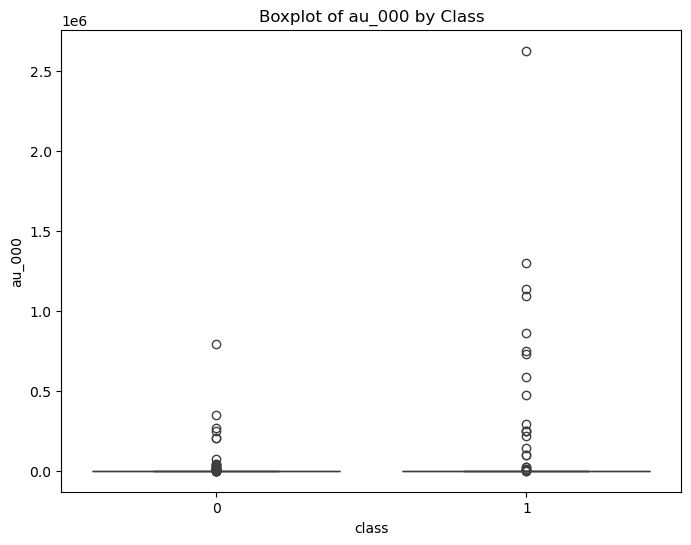

In [67]:
for i in cv_df_top_features['Feature Names']:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='class', y=i, data=train_data)
    plt.title(f"Boxplot of {i} by Class")
    plt.show()

From the scatter plots, it is difficult to come up with a decision about the significance of the features. The boxplots also support this, where both boxes are a line at 0 with many outliers. The high CV only suggests that there is high variability compared to the mean, which is not the same as a strong relationship between Class. These visualizations show us that outliers can dominate the plot, but they do cannot establish any significance. 

#### (v) Is this data set imbalanced?

In [68]:
train_data['class'].value_counts()

class
0    59000
1     1000
Name: count, dtype: int64

There are 59000 rows that belong to the negative class, and 1000 rows that belong to the positive class. This data is heavily imbalanced.

### (c) Train a random forest

##### Test Data

In [69]:
X_test = test_data.drop(columns = {'class'})
X_test.fillna(X_test.median(), inplace = True)
y_test = test_data['class'].map({'neg': 0, 'pos': 1})

##### Random Forest Classifier Model

In [70]:
rf_model = RandomForestClassifier(n_estimators = 100, oob_score = True, random_state = 42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(oob_score=True, random_state=42)

##### Training Data Results

In [71]:
y_pred = rf_model.predict(X_train)
y_pred_proba = rf_model.predict_proba(X_train)[:, 1]

In [72]:
confusion_matrix_train = confusion_matrix(y_train, y_pred)
confusion_matrix_train

array([[59000,     0],
       [    1,   999]])

In [73]:
misclassification_rate = 1 - accuracy_score(y_train, y_pred)
misclassification_rate

1.666666666666483e-05

In [74]:
auc = roc_auc_score(y_train, y_pred_proba)
auc

np.float64(1.0)

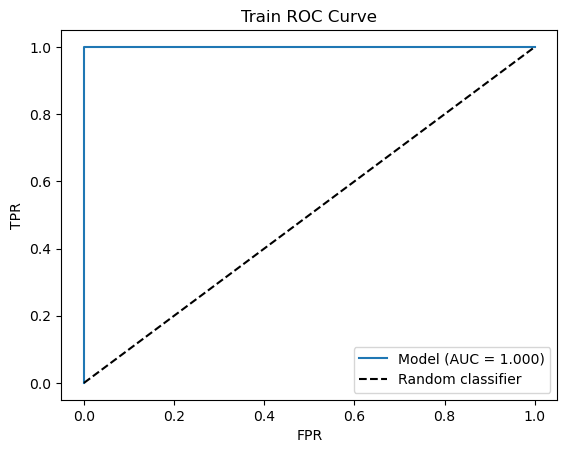

In [75]:
fpr, tpr, thresholds = roc_curve(y_train, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Train ROC Curve')
plt.legend()
plt.show()

In [76]:
oob_error = 1 - rf_model.oob_score_
oob_error

0.006116666666666659

##### Testing Data Results

In [77]:
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

In [78]:
confusion_matrix_test = confusion_matrix(y_test, y_pred)
confusion_matrix_test

array([[15610,    15],
       [  106,   269]])

In [79]:
misclassification_rate = 1 - accuracy_score(y_test, y_pred)
misclassification_rate

0.0075625000000000275

In [80]:
auc = roc_auc_score(y_test, y_pred_proba)
auc

np.float64(0.9927662079999999)

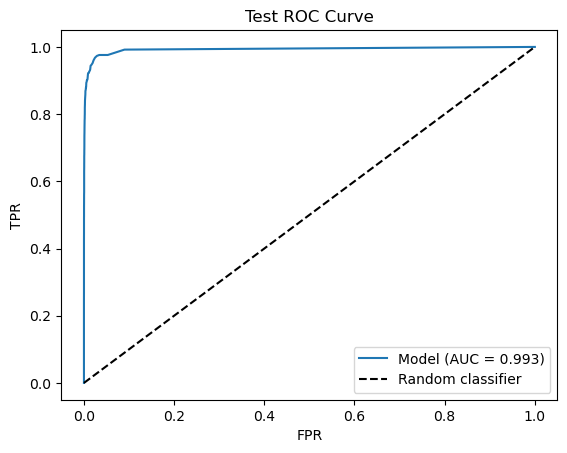

In [81]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Test ROC Curve')
plt.legend()
plt.show()

The OOB error estimate was 0.006116666666666659, whereas the test error was 0.0075625000000000275. This means that the model classified the out of bag samples better than the test samples. They both show that this is a strong classifier for this dataset.

### (d) Research class imbalance in random forest

In Random Forest, there is a parameter called class_weight. It is used to address class imbalance in a random forest. This parameter is responsible for assigning higher weights to classes that are infrequent.

In [82]:
rf_model = RandomForestClassifier(n_estimators = 100, oob_score = True, random_state = 42, class_weight = 'balanced_subsample')
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', oob_score=True,
                       random_state=42)

##### Train Data Results with Balanced Classes

In [83]:
y_pred = rf_model.predict(X_train)
y_pred_proba = rf_model.predict_proba(X_train)[:, 1]

confusion_matrix_train = confusion_matrix(y_train, y_pred)

misclassification_rate = 1 - accuracy_score(y_train, y_pred)

auc = roc_auc_score(y_train, y_pred_proba)

oob_error = 1 - rf_model.oob_score_

print('confusion_matrix_train:', confusion_matrix_train)
print('misclassification_rate:', misclassification_rate)
print('auc:', auc)
print('oob_error:', oob_error)

confusion_matrix_train: [[59000     0]
 [    1   999]]
misclassification_rate: 1.666666666666483e-05
auc: 1.0
oob_error: 0.007883333333333353


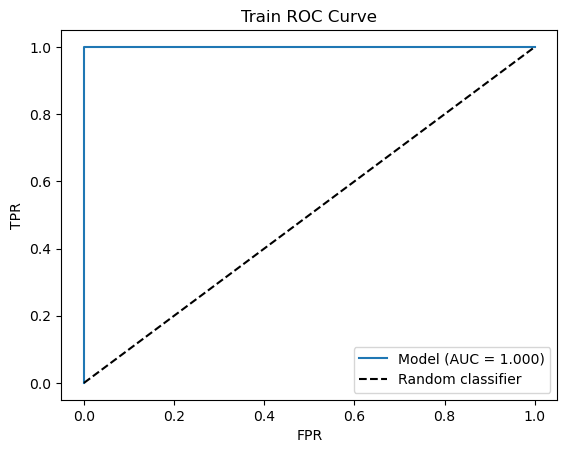

In [84]:
fpr, tpr, thresholds = roc_curve(y_train, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Train ROC Curve')
plt.legend()
plt.show()

##### Test Data Results with Balanced Classes

In [85]:
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

confusion_matrix_test = confusion_matrix(y_test, y_pred)

misclassification_rate = 1 - accuracy_score(y_test, y_pred)

auc = roc_auc_score(y_test, y_pred_proba)

oob_error = 1 - rf_model.oob_score_

print('confusion_matrix_test:', confusion_matrix_test)
print('misclassification_rate:', misclassification_rate)
print('auc:', auc)

confusion_matrix_test: [[15609    16]
 [  156   219]]
misclassification_rate: 0.010750000000000037
auc: 0.9904482986666666


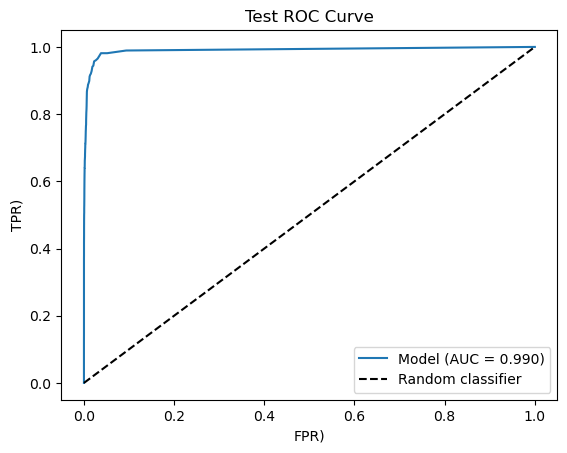

In [86]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR)')
plt.ylabel('TPR)')
plt.title('Test ROC Curve')
plt.legend()
plt.show()

The out of bag error is 0.007883333333333353, which means it has slightly increased from 0.006116666666666659. The test error actually goes from 0.0075625000000000275 to 0.010750000000000037. This means that the test error has slightly increased. By balancing the classes, we actually get a slightly worse model. We can see from the confusion matrix that the model with balanced classes produced more false negatives and decrease the number of true positives. 

### (e) XGBoost and Model Trees

In [88]:
xgboost_model = XGBClassifier(objective = 'binary:logistic', eval_metric = 'logloss', random_state = 42, n_jobs = -1)

In [90]:
xgboost_grid = GridSearchCV(
    xgboost_model,
    param_grid={"reg_alpha": [0, 0.01, 0.1, 1, 10, 100]},
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="f1",
    n_jobs=-1,
)
xgboost_grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True,
                                     eval_metric='logloss', feature_types=None,
                                     feature_weights=None, gamma=None,
                                     grow_p...
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=-1, num_parallel_tree=None, ...),
             n_jobs=-1, param_grid={'reg_alpha': [0, 0.01, 0.1, 1, 10, 100]},
             scoring='f1')

In [91]:
best_alpha = xgboost_grid.best_params_['reg_alpha']
best_cv_error = 1 - xgboost_grid.best_score_

print('best_alpha:', best_alpha)
print('best_cv_error:', best_cv_error)

best_alpha: 0.01
best_cv_error: 0.20227123365335875


##### Training Data

In [100]:
y_pred = xgboost_grid.predict(X_train)
y_pred_proba = xgboost_grid.predict_proba(X_train)[:, 1]

confusion_matrix_train = confusion_matrix(y_train, y_pred)

misclassification_rate = 1 - accuracy_score(y_train, y_pred)

f1_Score = f1_score(y_train, y_pred)

auc = roc_auc_score(y_train, y_pred_proba)

print('confusion_matrix_train:', confusion_matrix_train)
print('misclassification_rate:', misclassification_rate)
print('f1_Score:', f1_Score)
print('auc:', auc)

confusion_matrix_train: [[59000     0]
 [    1   999]]
misclassification_rate: 1.666666666666483e-05
f1_Score: 0.9994997498749375
auc: 0.9999999491525424


Exception ignored in: <function ResourceTracker.__del__ at 0x104d89bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


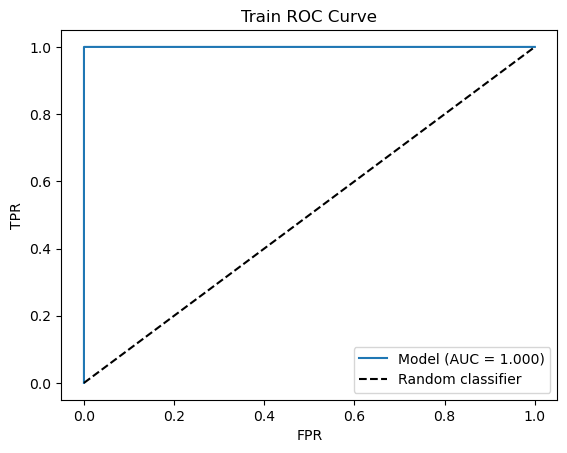

Exception ignored in: <function ResourceTracker.__del__ at 0x104c9dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1052bdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


In [101]:
fpr, tpr, thresholds = roc_curve(y_train, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Train ROC Curve')
plt.legend()
plt.show()

##### Testing Data

In [104]:
y_pred = xgboost_grid.predict(X_test)
y_pred_proba = xgboost_grid.predict_proba(X_test)[:, 1]

confusion_matrix_test = confusion_matrix(y_test, y_pred)

misclassification_rate = 1 - accuracy_score(y_test, y_pred)

f1_Score = f1_score(y_test, y_pred)

auc = roc_auc_score(y_test, y_pred_proba)

print('confusion_matrix_test:', confusion_matrix_test)
print('misclassification_rate:', misclassification_rate)
print('f1_Score:', f1_Score)
print('auc:', auc)

confusion_matrix_test: [[15609    16]
 [   86   289]]
misclassification_rate: 0.0063750000000000195
f1_Score: 0.85
auc: 0.9936580266666666


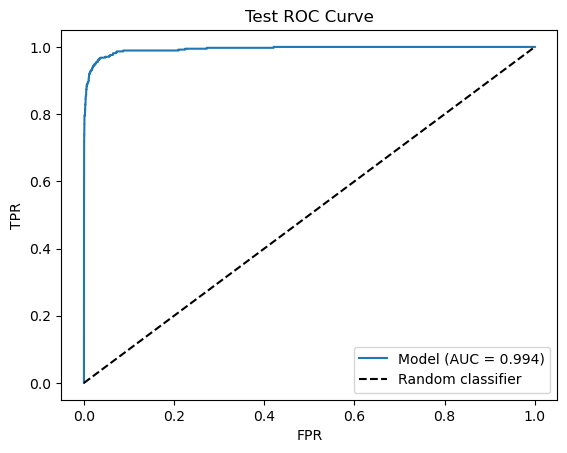

In [103]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Test ROC Curve')
plt.legend()
plt.show()

The best CV error was 0.006349999999999967. The test error was 0.0063750000000000195. They are very similiar, which tells us that this model is not overfit. 

### (f) Use SMOTE to pre-process your data

In [105]:
pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgboost', XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=42, n_jobs=-1))
])

smote_grid = GridSearchCV(
    pipeline,
    param_grid={"xgboost__reg_alpha": [0, 0.01, 0.1, 1, 10, 100]},
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="f1",
    n_jobs=-1,
)
smote_grid.fit(X_train, y_train)

Exception ignored in: <function ResourceTracker.__del__ at 0x105ab1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('smote', SMOTE(random_state=42)),
                                       ('xgboost',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=None,
                                                      device=None,
                                                      early_stopping_rounds=None,
                                                      enable_categorical=True,
                                                      eval_metric='loglos...
                                                      interaction_constraints=None,
                                                      learning_rate=None,
                                                      max_bin=None,
                                                      max_cat_threshold=None,
                                                      max_cat_to_onehot=None,
                                                      max_delta_step=None,
                                                      max_depth=None,
                                                      max_leaves=None,
                                                      min_child_weight=None,
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=None,
                                                      n_jobs=-1,
                                                      num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'xgboost__reg_alpha': [0, 0.01, 0.1, 1, 10, 100]},
             scoring='f1')

In [106]:
best_alpha = smote_grid.best_params_['xgboost__reg_alpha']
best_cv_error = 1 - smote_grid.best_score_

print('best_alpha:', best_alpha)
print('best_cv_error:', best_cv_error)

best_alpha: 1
best_cv_error: 0.18702082269051845


Exception ignored in: <function ResourceTracker.__del__ at 0x102d99bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x103281bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x109b71bc0>
Traceback (most recent call last

##### Training Data

In [45]:
y_pred = smote_grid.predict(X_train)
y_pred_proba = smote_grid.predict_proba(X_train)[:, 1]

confusion_matrix_train = confusion_matrix(y_train, y_pred)

misclassification_rate = 1 - accuracy_score(y_train, y_pred)

auc = roc_auc_score(y_train, y_pred_proba)

print('confusion_matrix_train:', confusion_matrix_train)
print('misclassification_rate:', misclassification_rate)
print('auc:', auc)

confusion_matrix_train: [[59000     0]
 [    1   999]]
misclassification_rate: 1.666666666666483e-05
auc: 0.9999762118644068


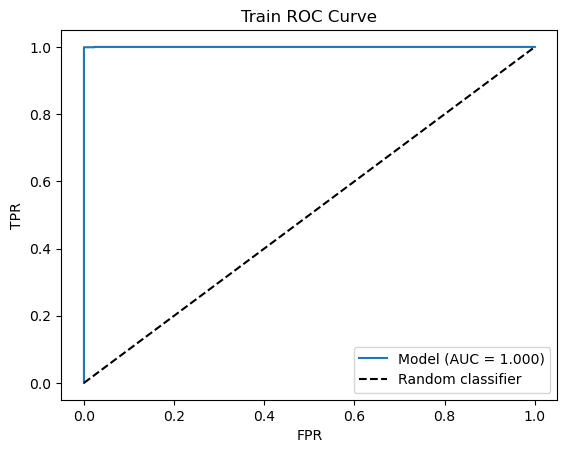

In [46]:
fpr, tpr, thresholds = roc_curve(y_train, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('Train ROC Curve')
plt.legend()
plt.show()

##### Testing Data Results

In [47]:
y_pred = smote_grid.predict(X_test)
y_pred_proba = smote_grid.predict_proba(X_test)[:, 1]

confusion_matrix_test = confusion_matrix(y_test, y_pred)

misclassification_rate = 1 - accuracy_score(y_test, y_pred)

auc = roc_auc_score(y_test, y_pred_proba)

print('confusion_matrix_test:', confusion_matrix_test)
print('misclassification_rate:', misclassification_rate)
print('auc:', auc)

confusion_matrix_test: [[15554    71]
 [   56   319]]
misclassification_rate: 0.007937500000000042
auc: 0.9944634026666667


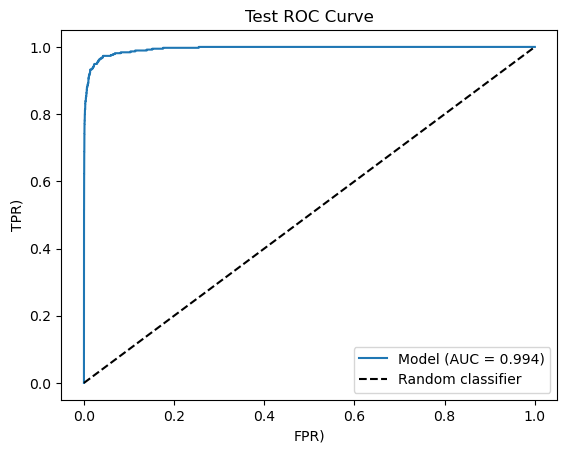

In [48]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f"Model (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel('FPR)')
plt.ylabel('TPR)')
plt.title('Test ROC Curve')
plt.legend()
plt.show()

When we did not compensate to pre-process our data for class imbalance, we got the best cv error rate of 0.006349999999999967. After applying SMOTE, we got the best cv error rate of 0.006333333333333302. On the other hand, the uncompensated case got a test error of 0.0063750000000000195. The SMOTE case got a test error of 0.007937500000000042. This means that SMOTE actually slightly reduced the model's overall test accuracy, whereas the uncompensated case had very similiar CV and test errors. From the confusion matrix, we can see that SMOTE helped improve detect positive cases. We went from predicting 289 positive cases correctly to 319. However, it came at the cost of more false positives. We increased it from 16 to 71. Therefore, SMOTE did help predict the minority class, but it reduced our overall accuracy. Also, I made sure to perform SMOTE inside the pipeline, so it performs cross validation the correct way.

## 2. ISLR 6.6.3

a) iv. As we increase s from 0, the training RSS will steadily decrease. When s = 0, it will just be the intercept as the model, which will be a high RSS. Increasing s will make the model more flexible and we penalize the coefficients less. This means that the training RSS will only decrease as s increases. 

b) ii. As we increase s from 0, the testing RSS will decrease iniially and then eventually start increasing in a U shape. When s is small, the model is underfit, so it results in high test RSS. As we continue to increase s, the model becomes more flexible, while allows the model to predict better and reduce test RSS. However, when s becomes too large, the model begins to train on all the noise in the training data and becomes overfit. Therefore, the test RSS begins to rise whereas training RSS would continue to drop. 

c) iii. As we increase s from 0, the variance will steadily increase. When s = 0, the model is just the intercept, so it will have a very low variance. As we increase s, the model becomes more flexible and sensitive to the noise in the training data, which means variance also increases.

d) iv. As we increase s from 0, the bias will steadily decrease. When s = 0, the model is just the intercept, so it is inflexible and has high squared bias. As we increase s, the model becomes more flexible. As a result, squared bias continues to decrease. 

e) v. As we increase s from 0, the irreducible error will remain constant. Irreducible error comes from the random noise in the data, and it cannot be reduced. Hence, it is called irreducible. Therefore, it will always remain constant regardless of what we do to s.  

## 3. ISLR 6.6.5

![My solution](../images/6.6.5.a.png)

![My solution](../images/6.6.5.b.png)

![My solution](../images/6.6.5.c.d.png)

## 4. ISLR 8.4.5

In [49]:
(0.1 +  0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10

0.45

If we take the majority vote approach, we would say that this specific value of X is Red. 6/10 estimates are greater than .5, which means by majority vote, we would classify it as red. If we take the average approach, we would say that this specific value of X is Green. The average of P(Class is Red | X) for 10 samples is .45. Therefore, we would classify it as green.

## 5. ISLR 9.7.3

![My solution](../images/9.7.3.png)

![My solution](../images/9.7.3.other.png)